<a href="https://colab.research.google.com/github/kamranalisays/machine-learning/blob/main/Hotel_Booking_Cancellation_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Booking Cancellation Prediction

The objective is to predict whether a hotel booking will be cancelled(is_canceled) based on customer information.

## **Importing libraries**

In [8]:
# import the libraries

# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns



## **Load the dataset**

In [9]:

df = pd.read_csv('train.csv')
pd.set_option('display.max_columns', None)
df.head(10)

,booking_id,booking_date,arrival_date,lead_time,stays_weekend,stays_weekday,adults,children,babies,meal_plan,country,market_segment,room_type,deposit_type,agent_id,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,special_requests,avg_daily_rate,parking_spaces,cancellation_fee_charged,is_canceled
0,8610,2023-05-14,2023-06-24,41,4,1,2,2.0,0,Bed & Breakfast,POL,Corporate,Standard,No Deposit,28,1,1.0,4,1,60.37,0,0,0
1,8405,2023-02-21,2023-04-13,51,0,2,4,0.0,0,Bed & Breakfast,FRA,Groups,Suite,No Deposit,12,0,3.0,3,3,81.49,0,0,0
2,8953,2023-11-18,2023-12-25,37,4,1,4,0.0,0,Bed & Breakfast,BRA,Online,Suite,No Deposit,15,0,1.0,0,1,127.29,0,1,1
3,9807,2023-03-10,2023-04-22,43,0,2,2,0.0,0,Bed & Breakfast,FRA,Corporate,Standard,Refundable,28,0,1.0,0,3,61.48,1,1,0
4,11161,2023-11-23,2023-11-26,3,1,7,2,0.0,0,Self Catering,POL,Offline,Standard,No Deposit,6,1,0.0,3,1,74.73,1,0,0
5,11635,2023-06-22,2023-08-05,44,2,4,1,0.0,0,Self Catering,PRT,Online,Standard,No Deposit,33,0,0.0,1,0,33.82,1,1,1
6,3929,2022-07-22,2022-09-30,70,0,4,3,0.0,0,Bed & Breakfast,POL,Online,Standard,No Deposit,30,0,0.0,1,3,84.61,0,0,0
7,11053,2022-02-12,2022-04-29,76,0,6,2,1.0,0,Bed & Breakfast,BEL,Offline,Deluxe,No Deposit,37,0,0.0,1,2,26.04,0,0,0
8,9472,2023-02-03,2023-03-02,27,3,3,2,0.0,0,Self Catering,ESP,Online,Standard,No Deposit,24,0,1.0,0,1,68.19,1,0,0
9,794,2023-10-18,2024-03-07,141,1,4,3,0.0,0,Bed & Breakfast,CHN,Online,Deluxe,No Deposit,28,0,0.0,1,1,62.17,0,1,1


## **Data Quality initial assessment**

In [10]:
df.shape

(9696, 23)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9696 entries, 0 to 9695
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   booking_id                      9696 non-null   int64  
 1   booking_date                    9696 non-null   object 
 2   arrival_date                    9696 non-null   object 
 3   lead_time                       9696 non-null   int64  
 4   stays_weekend                   9696 non-null   int64  
 5   stays_weekday                   9696 non-null   int64  
 6   adults                          9696 non-null   int64  
 7   children                        9199 non-null   float64
 8   babies                          9696 non-null   int64  
 9   meal_plan                       9696 non-null   object 
 10  country                         9696 non-null   object 
 11  market_segment                  9696 non-null   object 
 12  room_type                       96

In [12]:
df.describe()

,booking_id,lead_time,stays_weekend,stays_weekday,adults,children,babies,agent_id,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,special_requests,avg_daily_rate,parking_spaces,cancellation_fee_charged,is_canceled
count,9696.000000,9696.000000,9696.000000,9696.000000,9696.000000,9199.000000,9696.00000,9696.000000,9696.000000,8031.000000,9696.00000,9696.000000,9696.000000,9696.000000,9696.000000,9696.000000
mean,6055.811159,80.271865,1.294451,2.865099,1.960809,0.599304,0.17729,25.500516,0.150990,0.731540,1.47236,1.504435,104.049120,0.458952,0.383457,0.370771
std,3491.000383,79.195240,1.147248,1.577941,0.817871,0.866561,0.45784,14.402101,0.358058,1.070096,1.20958,1.269543,145.969124,0.674723,0.486253,0.483036
min,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.00000,0.000000,13.570000,0.000000,0.000000,0.000000
25%,3025.750000,23.000000,0.000000,2.000000,1.000000,0.000000,0.00000,13.000000,0.000000,0.000000,1.00000,0.000000,53.360000,0.000000,0.000000,0.000000
50%,6048.500000,56.000000,1.000000,3.000000,2.000000,0.000000,0.00000,25.000000,0.000000,0.000000,1.00000,1.000000,75.265000,0.000000,0.000000,0.000000
75%,9074.250000,113.000000,2.000000,4.000000,2.000000,1.000000,0.00000,38.000000,0.000000,1.000000,2.00000,2.000000,107.087500,1.000000,1.000000,1.000000
max,12120.000000,500.000000,4.000000,7.000000,4.000000,3.000000,2.00000,50.000000,1.000000,4.000000,7.00000,5.000000,1498.580000,2.000000,1.000000,1.000000


In [13]:
df.isna().sum()

,0
booking_id,0
booking_date,0
arrival_date,0
lead_time,0
stays_weekend,0
stays_weekday,0
adults,0
children,497
babies,0
meal_plan,0


In [14]:
df.columns[df.isna().any()].tolist()

['children', 'previous_cancellations']

In [15]:
df['children'].unique()

array([ 2.,  0.,  1.,  3., nan])

In [16]:
df['previous_cancellations'].unique()

array([ 1.,  3.,  0., nan,  2.,  4.])

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['meal_plan'].unique()

array(['Bed & Breakfast', 'Self Catering', 'Half Board', 'Full Board'],
      dtype=object)

In [19]:
df['market_segment'].unique()

array(['Corporate', 'Groups', 'Online', 'Offline', 'Aviation'],
      dtype=object)

In [20]:
df['room_type'].unique()

array(['Standard', 'Suite', 'Deluxe'], dtype=object)

In [21]:
df['deposit_type'].unique()

array(['No Deposit', 'Refundable', 'Non Refund'], dtype=object)

In [22]:
df['children'].unique()

array([ 2.,  0.,  1.,  3., nan])

## **Initial EDA**

### Univariate Analysis

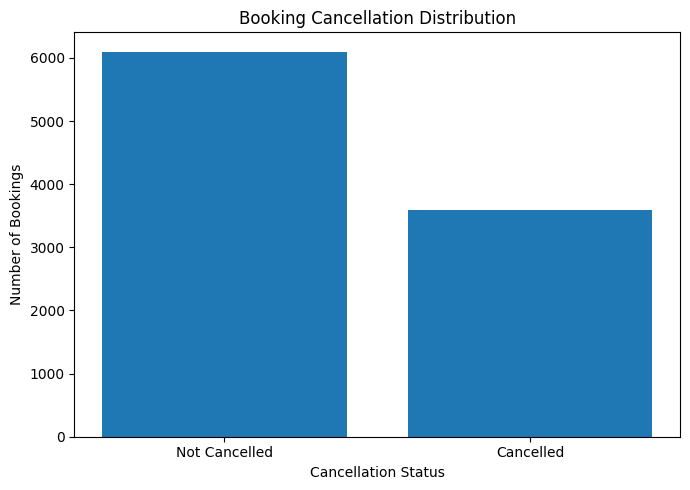

In [37]:
plt.figure(figsize=(7, 5))

counts = df['is_canceled'].value_counts().sort_index()
plt.bar(counts.index , counts.values)

plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation Status')
plt.ylabel('Number of Bookings')
plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'], rotation=0)
plt.tight_layout()
plt.show()

## **Data Cleaning**

Fix The Data Types

1) Object To Date Conversion

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9696 entries, 0 to 9695
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   booking_id                      9696 non-null   int64  
 1   booking_date                    9696 non-null   object 
 2   arrival_date                    9696 non-null   object 
 3   lead_time                       9696 non-null   int64  
 4   stays_weekend                   9696 non-null   int64  
 5   stays_weekday                   9696 non-null   int64  
 6   adults                          9696 non-null   int64  
 7   children                        9199 non-null   float64
 8   babies                          9696 non-null   int64  
 9   meal_plan                       9696 non-null   object 
 10  country                         9696 non-null   object 
 11  market_segment                  9696 non-null   object 
 12  room_type                       96

In [25]:
df['booking_date'] = pd.to_datetime(df['booking_date'])

In [26]:
df['booking_date'].dtype

dtype('<M8[ns]')

In [27]:
df['arrival_date'] =  pd.to_datetime(df['arrival_date'])

In [28]:
df['booking_date'].dtype

dtype('<M8[ns]')

2. Float To Int64

In [29]:
df['children'] = df['children'].astype('Int64')
df['children'] .dtype

Int64Dtype()

In [30]:
df['previous_cancellations'] = df['previous_cancellations'].astype('Int64')
df['previous_cancellations'] .dtype

Int64Dtype()

Handling Missing Values

1. Percentage of Missing Children Values.

In [31]:
(df['children'].isna().sum()/len(df)) *100

np.float64(5.125825082508251)

2. Percentage of Missing previous_cancellations Values.

In [32]:
(df['previous_cancellations'].isna().sum()/len(df)) *100

np.float64(17.1720297029703)